In [ ]:
# Setting up the work environment and installing required packages and get the torch version to work with PyTorch
import os
import torch
os.environ['TORCH'] = torch.__version__
print(torch.__version__)

2.10.0+cpu


In [ ]:
%matplotlib inline
#To include matplotlib graphs in the notebook, since it is a library to create visualizations in Python

import networkx as nx # The library networkx will be used to study the graphs and networks
import matplotlib.pyplot as plt #plt is the pyplot package "pyplot" from the library "matplotlib"


def visualize_graph(G, color): #This will construct a visual representation of the graph based on the data about it
    plt.figure(figsize=(7,7))
    nx.draw_networkx(G, with_labels=True, node_color=color, cmap="Set2")
    #G - represents the graph from networkxlibrary
    #with_labels - if the graph has labels indicating the number/position of the nodes
    #node_color - the visualization of the graph with the aid of the color will vary according to the color we choose
    #cmap - shows the intensities of the colors so they do not appear too bright or too dark so that they are distinguishable
    plt.show() #this will show everything in the graph

In [ ]:
pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 22.7 MB/s eta 0:00:00


In [ ]:
from torch_geometric.datasets import KarateClub

dataset_source = KarateClub() #The library to detect communities and embed networks based on the Karate Club event
print('Some information about the dataset: ')
print('Dataset source: ' + str(dataset_source))
print('Other information:')
print('-----------------------------------')
print('Graph count in the dataset: ' + str(len(dataset_source)))
print('Feature count: ' + str(dataset_source.num_features))
print('Class count: '+ str(dataset_source.num_classes)) #the classes represent the four communities that each node belongs to, so there are four classes


Some information about the dataset: 
Dataset source: KarateClub()
Other information:
-----------------------------------
Graph count in the dataset: 1
Feature count: 34
Class count: 4


In [ ]:
graph_data = dataset_source[0]  #There is only one graph, and we aim to retrieve it by 0-indexing, which means there is only one graph we have to deal with

print(graph_data)
#graph_data.x and graph_data.y are described in the below lines
#edge_index=[2, 156] means that there are two lists (one will store the source nodes and the other the destination nodes) and that there are 156 edges

print('Some statistics: ')
print('-------------------------------')

print('Node count: ' + str(graph_data.num_nodes)) #Number of all the nodes
print('Edge count: ' + str(graph_data.num_edges)) #Number of all edges that the nodes are connected to each other

print(f"Average number of edges per node: {graph_data.num_edges / graph_data.num_nodes:.2f} ") #The degree is the number of edges one node is connected to, so
#we calculate the total number of edges and the total number of nodes to get the number of edges per node
print('Training node count: ' + str(int(sum((graph_data.train_mask))))) #Nodes from the training data whose assignment to their own community is known by us; we know that
#one node belongs to a different community than the others, so there are 4 representative nodes that belong to 4 different communities; we infer to which community
#other nodes belong to based on the 4 ones whose communities are known to us

#Utility functions
print('-------------------------------')
print('Does the graph have isolated nodes? ' + str(graph_data.has_isolated_nodes())) #Checks whether a node has no connections or edges to other nodes
print('Does the graph have self-loops? ' + str(graph_data.has_self_loops())) #Checks whether a graph points to itself again
print('Is the graph undirected? ' + str(graph_data.is_undirected())) #Checks whether the graph has directions or not or if the road from the source node (u) to the
#destination node (v) is the same as (v) to (u) without any directions

Data(x=[34, 34], edge_index=[2, 156], y=[34], train_mask=[34])
Some statistics: 
-------------------------------
Node count: 34
Edge count: 156
Average number of edges per node: 4.59 
Training node count: 4
-------------------------------
Does the graph have isolated nodes? False
Does the graph have self-loops? False
Is the graph undirected? True


In [ ]:
print(graph_data.x) #x are the node features; each of 34 nodes has a 34-dimensional feature vector
#it is visible for graph_data.x that the output is an adjacency matrix of zeros and ones, it is an identity matrix without any relevant information about the nodes; it
#could contain information for certain characteristics, such as age or skill, not relevant data for this dataset.

print(graph_data.y) #each node is assigned to either 1 of 4 classes

tensor([[1., 0., 0.,  ..., 0., 0., 0.],
        [0., 1., 0.,  ..., 0., 0., 0.],
        [0., 0., 1.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 1., 0., 0.],
        [0., 0., 0.,  ..., 0., 1., 0.],
        [0., 0., 0.,  ..., 0., 0., 1.]])
tensor([1, 1, 1, 1, 3, 3, 3, 1, 0, 1, 3, 1, 1, 1, 0, 0, 3, 1, 0, 1, 0, 1, 0, 0,
        2, 2, 0, 0, 2, 0, 0, 2, 0, 0])


In [ ]:
#edge_index consists of a pair of node index values, wherein the first represents the node index value of the source node, and
#the second represents the node index value of the destination node of an edge.
source_destination_indices = graph_data.edge_index
print(source_destination_indices)

tensor([[ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,
          1,  1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  3,
          3,  3,  3,  3,  3,  4,  4,  4,  5,  5,  5,  5,  6,  6,  6,  6,  7,  7,
          7,  7,  8,  8,  8,  8,  8,  9,  9, 10, 10, 10, 11, 12, 12, 13, 13, 13,
         13, 13, 14, 14, 15, 15, 16, 16, 17, 17, 18, 18, 19, 19, 19, 20, 20, 21,
         21, 22, 22, 23, 23, 23, 23, 23, 24, 24, 24, 25, 25, 25, 26, 26, 27, 27,
         27, 27, 28, 28, 28, 29, 29, 29, 29, 30, 30, 30, 30, 31, 31, 31, 31, 31,
         31, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 33, 33, 33, 33, 33,
         33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33],
        [ 1,  2,  3,  4,  5,  6,  7,  8, 10, 11, 12, 13, 17, 19, 21, 31,  0,  2,
          3,  7, 13, 17, 19, 21, 30,  0,  1,  3,  7,  8,  9, 13, 27, 28, 32,  0,
          1,  2,  7, 12, 13,  0,  6, 10,  0,  6, 10, 16,  0,  4,  5, 16,  0,  1,
          2,  3,  0,  2, 30, 32, 33,  2, 33,  0,  4

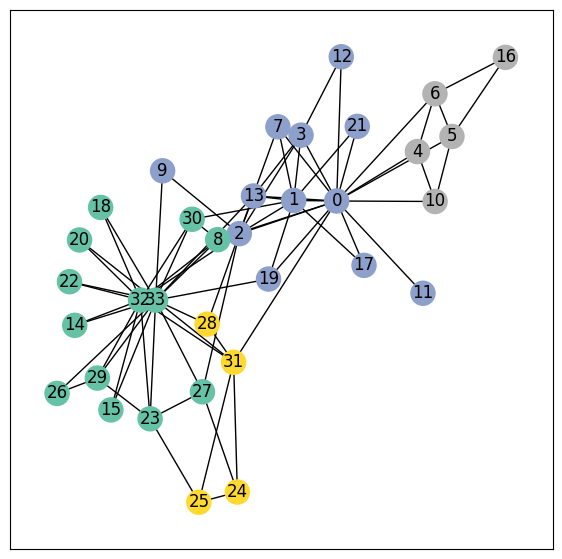

In [ ]:
from torch_geometric.utils import to_networkx #makes a networkx graph given the data structure of graph

undirected_graph = to_networkx(graph_data, to_undirected=True)
visualize_graph(undirected_graph, color=graph_data.y) #there are 4 colors to represent 1 community per each color

In [ ]:
#The method where 2 lists are used to store source and destination nodes separately is COO (a coordinate list), and this is applied to store a sparse matrix
#(a matrix full of zeros) efficiently, and the COO format uses only non-zero elements; this results in not only saved memory, but also computational resources.

#Connectivity of graphs is usually represented by an adjacency (square) matrix of 0's and 1's (1 indicates if a node i has a connection with a node j and 0 if it doesn't)
#However, adjacency matrices are not as efficient as COO in managing sparse data and space efficiency. The big presence of zeroes indicates that in a graph, the nodes
#are not densely connected to each other, so therefore, the COO format is applied by PyG.

#As mentioned before, the train_mask represents only the nodes for which communities are known(4 of them, hence 4 True's); the nodes with "True" are part of the training
#set and the others part of the testing set, so this division of data helps by providing data not seen before by the model for testing

print(graph_data.train_mask.shape)
print(graph_data.train_mask)


torch.Size([34])
tensor([ True, False, False, False,  True, False, False, False,  True, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False,  True, False, False, False, False, False,
        False, False, False, False])


## Implementing Graph Neural Networks

After the data handling part of PyTorch Geometric (PyG), the Graph Neural Network implementation is shown in the next lines of code.

For this, we will use on of the most simple GNN operators, the **GCN layer**, which is defined as

$$
\mathbf{x}_v^{(\ell + 1)} = \mathbf{W}^{(\ell + 1)} \sum_{w \in \mathcal{N}(v) \, \cup \, \{ v \}} \frac{1}{c_{w,v}} \cdot \mathbf{x}_w^{(\ell)}
$$

$\mathbf{W}^{(\ell + 1)}$ denotes a trainable weight matrix of shape `[num_output_features, num_input_features]` and $c_{w,v}$ refers to a fixed normalization coefficient for each edge.

PyG implements this layer via **GCNConv**, which can be executed by passing in the node feature representation `x` and the COO graph connectivity representation `edge_index`.

In [ ]:
from torch.nn import Linear
from torch_geometric.nn import GCNConv

#The Graph Convolutional Network has a single GCN layer, a ReLU activation function, and a linear output layer

class GCN(torch.nn.Module): #Graph Neural Network can be started to be built based on the definition of the architecture that is done in the torch.nn.Module class.
    def __init__(self):
        super().__init__()
        self.gcn = GCNConv(dataset_source.num_features, 3) #Dimensionality reduction from 34 to 3 features
        self.out = Linear(3, dataset_source.num_classes) #The Linear class is a single linear transformation that acts as a classifier to assign each node to its community
        #The output layer will produce four outputs, representing the four classes, and whichever one has the highest output value decides which class the node belongs to.
    def forward(self, x, edge_index):
        h = self.gcn(x, edge_index).relu() #relu() activation function used
        z = self.out(h) #Applying the linear transformation to the GCN layer
        return h, z
model = GCN()
print(model)

#bias= True means that the graph neural networks perform well on high-degree nodes (nodes with many edges) but not that well on low-degree nodes (nodes with low edges)

GCN(
  (gcn): GCNConv(34, 3)
  (out): Linear(in_features=3, out_features=4, bias=True)
)


We first define and stack **three graph convolution layers**, which corresponds to aggregating 3-hop neighborhood information around each node (all nodes up to 3 "hops" away); the hops represent the maximum number of movements that the information can go from a node to another.

In addition, the `GCNConv` layers reduce the node feature dimensionality from $34$ to $3$.

After that, we apply a single linear transformation, **torch.nn.Linear**, that acts as a classifier to map our nodes to 1 out of the 4 classes/communities. We proceed to initialize our final model via **GCN()**.


In [ ]:
criterion = torch.nn.CrossEntropyLoss() #regular cross-entropy method used for multi-class classification task
optimizer = torch.optim.Adam(model.parameters(), lr=0.02) #the optimizer of the cross-entropy method

#We aim to evaluate the accuracy of the model based on the formula: accuracy= number of correct predictions/ total number of predictions
def accuracy(pred_y, y):
    return (pred_y == y).sum() / len(y)

#empty list of data that is used to animate the network; it will try to predict the results of the GCN model compared to data.y (the labels)
#loss functions quantify the degree of the performance of the model by computing the difference between the predicted and actual values
#metrics, such as loss or accuracy, are printed every 10 epochs
embeddings = []
losses = []
accuracies = []
outputs = []

#The training loop
for epoch in range(201):
    optimizer.zero_grad() #To clear gradients for more efficient management of the memory and to avoid incorrect memory training
    h, z = model(graph_data.x, graph_data.edge_index)
    loss = criterion(z, graph_data.y) #To calculate the loss function
    acc = accuracy(z.argmax(dim=1), graph_data.y) #To calculate accuracy

    loss.backward() #Model's parameters are adjusted to lower the prediction error, so the adjustments are based on gradients; these are calculated during the backward
    #pass of the training loop through the use of backpropagation

    optimizer.step() #The optimizer uses gradients in order to perform a step that reduces the loss in a parameter space

    #Data that will be appended for the graph animation that will show the predictions of the GNN during the training process
    embeddings.append(h)
    losses.append(loss)
    accuracies.append(acc)
    outputs.append(z.argmax(dim=1))

    #Metrics will be printed every 10 epochs
    if epoch % 10 == 0:
        print(f'Epoch {epoch:>3} | Loss: {loss:.2f} | Acc: {acc*100:.2f}%')

Epoch   0 | Loss: 1.58 | Acc: 14.71%
Epoch  10 | Loss: 1.32 | Acc: 35.29%
Epoch  20 | Loss: 1.13 | Acc: 35.29%
Epoch  30 | Loss: 1.00 | Acc: 61.76%
Epoch  40 | Loss: 0.81 | Acc: 70.59%
Epoch  50 | Loss: 0.58 | Acc: 73.53%
Epoch  60 | Loss: 0.40 | Acc: 79.41%
Epoch  70 | Loss: 0.28 | Acc: 97.06%
Epoch  80 | Loss: 0.19 | Acc: 100.00%
Epoch  90 | Loss: 0.14 | Acc: 100.00%
Epoch 100 | Loss: 0.10 | Acc: 100.00%
Epoch 110 | Loss: 0.08 | Acc: 100.00%
Epoch 120 | Loss: 0.07 | Acc: 100.00%
Epoch 130 | Loss: 0.05 | Acc: 100.00%
Epoch 140 | Loss: 0.05 | Acc: 100.00%
Epoch 150 | Loss: 0.04 | Acc: 100.00%
Epoch 160 | Loss: 0.03 | Acc: 100.00%
Epoch 170 | Loss: 0.03 | Acc: 100.00%
Epoch 180 | Loss: 0.03 | Acc: 100.00%
Epoch 190 | Loss: 0.02 | Acc: 100.00%
Epoch 200 | Loss: 0.02 | Acc: 100.00%


In [ ]:
%%capture
#libraries that will be used for the animation
from IPython.display import HTML
from matplotlib import animation
plt.rcParams["animation.bitrate"] = 3000
import numpy as np

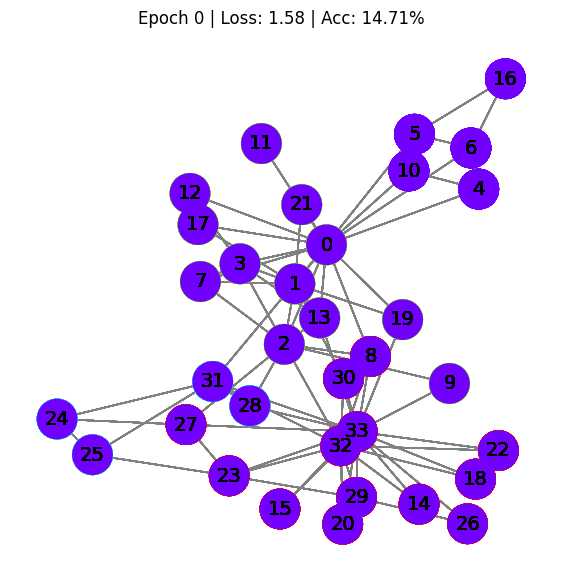

In [ ]:
def animate(i):
    G = to_networkx(graph_data, to_undirected=True)
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=0), with_labels=True, node_size=800, node_color=outputs[i], cmap="hsv", vmin=0, vmax=4, edge_color="grey", font_size=14
    )
    #nx.spring_layout(G, seed=0) will ensure that nodes are not scattered and in the correct order
    #node_color will be according to the class of the nodes, we have 4 classes and 4 colors
    plt.title(f'Epoch {i} | Loss: {losses[i]:.2f} | Acc: {accuracies[i]*100:.2f}%')
fig = plt.figure(figsize=(7, 7))
plt.axis('off') #no x- and y-axis value are needed for the graph; the numbers and the colors inside them convey enough information
anim = animation.FuncAnimation(fig, animate, \
                               np.arange(0, 200, 10), interval=500, repeat=True) #starting from epoch 0 to 200, in batches of 10; interval means the delay between the
                               #outputs for each epoch (every 500 milliseconds or 0.5 seconds), and repeat=True shows if the epoch outputs will
                               #start from 0 again or will end when the epoch is 200
html = HTML(anim.to_html5_video()) #the animation is returned as an HTML video tag
display(html)

In [ ]:
print('Embeddings:\n')
print(h)

#Dimensions of embeddings and feature vectors do not need to be the same; the reduction of dimension from 34 to 3 is to get a 3D visualization of the outcome

Embeddings:

tensor([[0.0000e+00, 2.0549e-01, 3.0830e+00],
        [0.0000e+00, 0.0000e+00, 2.2843e+00],
        [3.4565e-02, 0.0000e+00, 1.5932e+00],
        [0.0000e+00, 0.0000e+00, 2.3994e+00],
        [5.9645e-01, 2.6129e+00, 2.3338e+00],
        [5.8067e-01, 2.9505e+00, 2.5747e+00],
        [5.6928e-01, 2.9189e+00, 2.6082e+00],
        [0.0000e+00, 0.0000e+00, 2.0896e+00],
        [1.4601e+00, 1.0007e+00, 1.8374e-01],
        [1.1975e-01, 0.0000e+00, 1.4792e+00],
        [5.9191e-01, 2.6832e+00, 2.2738e+00],
        [2.2263e-02, 3.4046e-04, 2.0630e+00],
        [0.0000e+00, 1.0073e-04, 1.9430e+00],
        [8.8142e-02, 0.0000e+00, 1.6999e+00],
        [1.7065e+00, 1.1106e+00, 3.3171e-02],
        [1.5357e+00, 1.2985e+00, 2.4620e-02],
        [6.5759e-01, 2.7699e+00, 2.3507e+00],
        [0.0000e+00, 0.0000e+00, 1.8881e+00],
        [1.5590e+00, 1.2207e+00, 3.1540e-02],
        [1.8419e-01, 0.0000e+00, 1.7053e+00],
        [1.6306e+00, 1.1645e+00, 4.8554e-02],
        [0.0000e+00, 

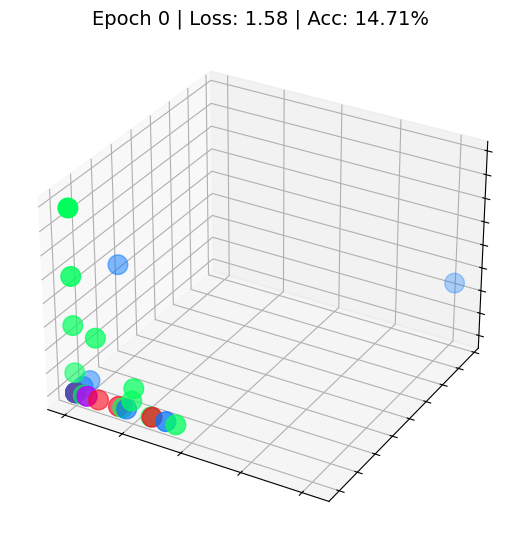

In [ ]:
#Here, we observe each and every node from the karate club dataset with their actual label information and not by the prediction of the model.
#At the current stage, all these nodes are located anywhere because the GNN network is untrained.
#However, if plotted step-by-step during the training process with the test data, we could actually observe the learning of the GNN.

def animate(i):
    embed = embeddings[i].detach().cpu().numpy()
    ax.clear() #when classes change, without this method the position of the classes (nodes that have these classes) is kept also from the previous epochs, and the
    #clustering of nodes is not shown properly.
    ax.scatter(embed[:, 0], embed[:, 1], embed[:, 2], s=200, c=graph_data.y, cmap="hsv", vmin=-2, vmax=3)
    #the three embeddings
    #s will show the size of nodes
    #c for the colors of the classes
    plt.title(f'Epoch {i} | Loss: {losses[i]:.2f} | Acc: {accuracies[i]*100:.2f}%',
              fontsize=14)
fig = plt.figure(figsize=(6.5, 6.5))
ax = fig.add_subplot(projection='3d') #to show the epoch in 3D
plt.tick_params(labelleft=False, labelbottom=False) #to ensure that no numbers are in the x- and y- axes since they are not needed
anim = animation.FuncAnimation(fig, animate, \
              np.arange(0, 200, 10), interval=800, repeat=True)

html = HTML(anim.to_html5_video())
display(html)